# VCU Battery Characteristics

Edit `DATA_DIR` and `LOG_NUMBER` in the user block, then run all cells. The notebook loads the CSV streams for one `LOG####`, aligns medium-frequency rows onto fast samples, estimates open-circuit voltage from the earliest future 0.5 s zero-current rest window, and summarizes internal resistance.

In [1]:
from pathlib import Path
import math
import re

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [28]:
# USER EDIT BLOCK
# Directory containing decoded LOG####_fast.csv and LOG####_medium.csv files.
DATA_DIR = r"VCU/June11thTestingDataLog_AfterChargingBattery"

# Accepts 10, "10", "0010", or "LOG0010".
LOG_NUMBER = "LOG0012"

# Each fast sample is paired with the nearest medium sample inside this tolerance.
MAX_MATCH_DELTA_MS = 75

# A sample is approximately zero-current when abs(bus_current_a) is at or below this threshold.
ZERO_CURRENT_THRESHOLD_A = 1.0

# OCV is estimated from the maximum voltage in the earliest future rest window of this length.
OCV_REST_WINDOW_S = 0.5

# Resistance is undefined near zero current. Raise this if low-current noise dominates.
MIN_ABS_CURRENT_A = 10.0

# Drop precharge/fault-state rows where the HV bus voltage is not a meaningful pack voltage.
MIN_PACK_VOLTAGE_V = 10.0

# Set to an integer to downsample plots, or leave as None to plot all rows.
MAX_PLOT_POINTS = 8000
MAX_SCATTER_POINTS = 12000


In [29]:
LOG_ID_RE = re.compile(r"^LOG(?P<num>\d+)$", re.IGNORECASE)
STREAMS = ("fast", "medium", "slow", "imu")


def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "VCU").exists() and (path / "README.md").exists():
            return path
    return start


REPO_ROOT = find_repo_root()


def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
        REPO_ROOT / "VCU" / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()


def format_log_id(log_number):
    text = str(log_number).strip()
    match = LOG_ID_RE.match(text)
    if match:
        number = int(match.group("num"))
    else:
        number = int(text)
    return f"LOG{number:04d}", number


def _numeric(series):
    return pd.to_numeric(series, errors="coerce")


def require_columns(df, stream, columns):
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise KeyError(f"{stream} CSV is missing required column(s): {', '.join(missing)}")


def load_single_vcu_log(data_dir, log_number, required_streams=("fast", "medium")):
    data_dir = resolve_data_dir(data_dir)
    if not data_dir.exists():
        raise FileNotFoundError(f"Directory not found: {data_dir}")

    log_id, numeric_id = format_log_id(log_number)
    data = {}
    files = {}

    for stream in STREAMS:
        path = data_dir / f"{log_id}_{stream}.csv"
        if path.exists():
            files[stream] = path
            data[stream] = pd.read_csv(path)

    missing = [stream for stream in required_streams if stream not in data]
    if missing:
        missing_files = ", ".join(f"{log_id}_{stream}.csv" for stream in missing)
        raise FileNotFoundError(f"Missing required CSV file(s): {missing_files}")

    print(f"Loaded {log_id} from {data_dir}")
    for stream in sorted(data, key=STREAMS.index):
        print(f"  {stream}: {len(data[stream]):,} rows ({files[stream].name})")

    return {
        "log_id": log_id,
        "numeric_id": numeric_id,
        "directory": data_dir,
        "files": files,
        "data": data,
    }


In [35]:
def merge_medium_with_fast(log, max_match_delta_ms=75):
    fast = log["data"]["fast"].copy()
    medium = log["data"]["medium"].copy()
    require_columns(fast, "fast", ["t_ms", "bus_voltage_v", "bus_current_a"])
    require_columns(medium, "medium", ["t_ms"])

    fast["fast_t_ms"] = _numeric(fast["t_ms"])
    fast = fast.drop(columns=["t_ms"]).dropna(subset=["fast_t_ms"]).sort_values("fast_t_ms")

    medium["medium_t_ms"] = _numeric(medium["t_ms"])
    medium = medium.drop(columns=["t_ms"]).dropna(subset=["medium_t_ms"]).sort_values("medium_t_ms")
    medium = medium.rename(
        columns={column: f"medium_{column}" for column in medium.columns if column != "medium_t_ms"}
    )

    merged = pd.merge_asof(
        fast,
        medium,
        left_on="fast_t_ms",
        right_on="medium_t_ms",
        direction="nearest",
        tolerance=max_match_delta_ms,
    )

    first_t = merged["fast_t_ms"].dropna().iloc[0]
    merged.insert(1, "elapsed_s", (merged["fast_t_ms"] - first_t) / 1000.0)
    merged["medium_match_delta_ms"] = merged["fast_t_ms"] - merged["medium_t_ms"]

    print(f"Merged {len(merged):,} fast rows with nearest medium rows")
    matched = merged["medium_t_ms"].notna().sum()
    print(f"  matched medium rows within {max_match_delta_ms} ms: {matched:,} ({matched / len(merged):.1%})")
    return merged.reset_index(drop=True)


def estimate_future_rest_ocv(
    df,
    voltage_col="bus_voltage_v",
    current_col="bus_current_a",
    time_col="fast_t_ms",
    zero_current_threshold_a=1.0,
    rest_window_s=0.5,
):
    time_s = _numeric(df[time_col]).to_numpy(dtype=float) / 1000.0
    voltage = _numeric(df[voltage_col]).to_numpy(dtype=float)
    current = _numeric(df[current_col]).to_numpy(dtype=float)
    n = len(df)

    valid_signal = np.isfinite(time_s) & np.isfinite(voltage) & np.isfinite(current)
    zero_current = valid_signal & (np.abs(current) <= zero_current_threshold_a)
    ocv_at_window_start = np.full(n, np.nan)

    run_start = None
    for idx, is_zero in enumerate(zero_current):
        if is_zero and run_start is None:
            run_start = idx
        run_ended = run_start is not None and (not is_zero or idx == n - 1)
        if not run_ended:
            continue

        run_end = idx if not is_zero else idx + 1
        run_times = time_s[run_start:run_end]
        for start in range(run_start, run_end):
            window_stop_time = time_s[start] + rest_window_s
            if run_times[-1] < window_stop_time:
                break
            window_end = min(np.searchsorted(time_s, window_stop_time, side="right"), run_end)
            ocv_at_window_start[start] = np.nanmax(voltage[start:window_end])
        run_start = None

    valid_starts = np.flatnonzero(np.isfinite(ocv_at_window_start))
    ocv = np.full(n, np.nan)
    source_indices = np.full(n, np.nan)
    if len(valid_starts):
        positions = np.searchsorted(valid_starts, np.arange(n), side="left")
        has_future_window = positions < len(valid_starts)
        matched_starts = valid_starts[positions[has_future_window]]
        ocv[has_future_window] = ocv_at_window_start[matched_starts]
        source_indices[has_future_window] = matched_starts

    source_t_ms = np.full(n, np.nan)
    source_delay_s = np.full(n, np.nan)
    has_source = np.isfinite(source_indices)
    if has_source.any():
        source_int = source_indices[has_source].astype(int)
        source_t_ms[has_source] = time_s[source_int] * 1000.0
        source_delay_s[has_source] = time_s[source_int] - time_s[has_source]

    ocv = np.fmax(ocv, voltage)

    return ocv, source_t_ms, source_delay_s


def add_battery_characteristics(df, voltage_col="bus_voltage_v", current_col="bus_current_a"):
    result = df.copy()
    result[voltage_col] = _numeric(result[voltage_col])
    result[current_col] = _numeric(result[current_col])

    ocv, source_t_ms, source_delay_s = estimate_future_rest_ocv(
        result,
        voltage_col=voltage_col,
        current_col=current_col,
        zero_current_threshold_a=ZERO_CURRENT_THRESHOLD_A,
        rest_window_s=OCV_REST_WINDOW_S,
    )
    result["open_circuit_voltage_v"] = ocv
    result["ocv_window_start_t_ms"] = source_t_ms
    result["ocv_source_delay_s"] = source_delay_s
    result["voltage_drop_v"] = result["open_circuit_voltage_v"] - result[voltage_col]

    current = result[current_col]
    with np.errstate(divide="ignore", invalid="ignore"):
        result["internal_resistance_ohm"] = result["voltage_drop_v"] / current
    result.loc[current.abs() < MIN_ABS_CURRENT_A, "internal_resistance_ohm"] = np.nan
    result["internal_resistance_ohm"] = result["internal_resistance_ohm"].replace([np.inf, -np.inf], np.nan)
    return result


def valid_resistance_samples(df):
    required = ["bus_voltage_v", "bus_current_a", "open_circuit_voltage_v", "internal_resistance_ohm"]
    valid = df.dropna(subset=required).copy()
    valid = valid[valid["bus_current_a"] >= MIN_ABS_CURRENT_A]
    valid = valid[valid["bus_voltage_v"] >= MIN_PACK_VOLTAGE_V]
    valid = valid[np.isfinite(valid["internal_resistance_ohm"])]
    return valid.reset_index(drop=True)


def summarize_internal_resistance(samples):
    if samples.empty:
        return pd.DataFrame(
            [{"metric": "valid_resistance_samples", "value": 0, "unit": "rows"}]
        )

    resistance = samples["internal_resistance_ohm"]
    n = len(resistance)
    mean = resistance.mean()
    std = resistance.std(ddof=1) if n > 1 else 0.0
    sem = std / math.sqrt(n) if n > 1 else 0.0
    ci95_half_width = 1.96 * sem

    rows = [
        ("valid_resistance_samples", n, "rows"),
        ("mean_internal_resistance", mean, "ohm"),
        ("std_internal_resistance", std, "ohm"),
        ("standard_error", sem, "ohm"),
        ("ci95_half_width", ci95_half_width, "ohm"),
        ("mean_ocv_source_delay", samples["ocv_source_delay_s"].mean(), "s"),
        ("max_ocv_source_delay", samples["ocv_source_delay_s"].max(), "s"),
        ("min_current", samples["bus_current_a"].min(), "A"),
        ("max_current", samples["bus_current_a"].max(), "A"),
        ("mean_pack_voltage", samples["bus_voltage_v"].mean(), "V"),
        ("mean_open_circuit_voltage", samples["open_circuit_voltage_v"].mean(), "V"),
    ]
    return pd.DataFrame(rows, columns=["metric", "value", "unit"])


In [36]:
def _plot_sample(df, max_points=None):
    if max_points is None or len(df) <= max_points:
        return df
    step = max(1, math.ceil(len(df) / max_points))
    return df.iloc[::step].copy()


def plot_voltage_and_ocv(df, log_id=None, max_points=8000):
    plot_df = _plot_sample(df, max_points=max_points)
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    ax.plot(
        plot_df["elapsed_s"],
        plot_df["bus_voltage_v"],
        linewidth=1.0,
        label="Instantaneous pack voltage",
    )
    ax.plot(
        plot_df["elapsed_s"],
        plot_df["open_circuit_voltage_v"],
        linewidth=1.4,
        label="Earliest future zero-current OCV estimate",
    )
    title = "Pack voltage and open-circuit voltage estimate"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel("Voltage (V)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax


def plot_internal_resistance_vs_current(samples, log_id=None, max_points=12000):
    if samples.empty:
        raise ValueError("No valid resistance samples. Lower MIN_ABS_CURRENT_A or MIN_PACK_VOLTAGE_V if appropriate.")

    plot_df = _plot_sample(samples, max_points=max_points)
    mean_r = samples["internal_resistance_ohm"].mean()
    std_r = samples["internal_resistance_ohm"].std(ddof=1) if len(samples) > 1 else 0.0

    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    points = ax.scatter(
        plot_df["bus_current_a"],
        plot_df["internal_resistance_ohm"],
        c=plot_df["elapsed_s"],
        cmap="viridis",
        s=18,
        alpha=0.65,
        edgecolors="none",
    )
    cbar = fig.colorbar(points, ax=ax)
    cbar.set_label("Elapsed time (s)")
    ax.axhline(mean_r, color="black", linestyle="--", linewidth=1.1, label=f"Mean = {mean_r:.5f} ohm")
    ax.axhline(mean_r + std_r, color="gray", linestyle=":", linewidth=1.0, label="Mean +/- 1 std dev")
    ax.axhline(mean_r - std_r, color="gray", linestyle=":", linewidth=1.0)

    title = "Internal resistance vs pack current"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Instantaneous pack current (A)")
    ax.set_ylabel("Internal resistance (ohm)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax


In [37]:
log = load_single_vcu_log(DATA_DIR, LOG_NUMBER)
merged_log = merge_medium_with_fast(log, max_match_delta_ms=MAX_MATCH_DELTA_MS)
battery_df = add_battery_characteristics(merged_log)
resistance_samples = valid_resistance_samples(battery_df)

summary = summarize_internal_resistance(resistance_samples)
display(summary.round({"value": 6}))

if not resistance_samples.empty:
    mean_r = resistance_samples["internal_resistance_ohm"].mean()
    std_r = resistance_samples["internal_resistance_ohm"].std(ddof=1) if len(resistance_samples) > 1 else 0.0
    sem_r = std_r / math.sqrt(len(resistance_samples)) if len(resistance_samples) > 1 else 0.0
    ci95 = 1.96 * sem_r
    print(
        f"Average internal resistance: {mean_r:.6f} ohm +/- {ci95:.6f} ohm "
        f"(95% CI), std dev {std_r:.6f} ohm, n={len(resistance_samples):,}"
    )

display(
    battery_df[
        [
            "elapsed_s",
            "fast_t_ms",
            "medium_t_ms",
            "bus_voltage_v",
            "bus_current_a",
            "open_circuit_voltage_v",
            "ocv_window_start_t_ms",
            "ocv_source_delay_s",
            "voltage_drop_v",
            "internal_resistance_ohm",
        ]
    ].head()
)


Loaded LOG0012 from C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery
  fast: 95,211 rows (LOG0012_fast.csv)
  medium: 10,533 rows (LOG0012_medium.csv)
  slow: 1,066 rows (LOG0012_slow.csv)
  imu: 95,211 rows (LOG0012_imu.csv)
Merged 95,211 fast rows with nearest medium rows
  matched medium rows within 75 ms: 95,210 (100.0%)


,metric,value,unit
0,valid_resistance_samples,28309.000000,rows
1,mean_internal_resistance,0.267247,ohm
2,std_internal_resistance,0.068184,ohm
3,standard_error,0.000405,ohm
4,ci95_half_width,0.000794,ohm
5,mean_ocv_source_delay,4.522192,s
6,max_ocv_source_delay,27.765000,s
7,min_current,10.000000,A
8,max_current,169.400000,A
9,mean_pack_voltage,359.237278,V


Average internal resistance: 0.267247 ohm +/- 0.000794 ohm (95% CI), std dev 0.068184 ohm, n=28,309


,elapsed_s,fast_t_ms,medium_t_ms,bus_voltage_v,bus_current_a,open_circuit_voltage_v,ocv_window_start_t_ms,ocv_source_delay_s,voltage_drop_v,internal_resistance_ohm
0,0.00,3274,3274.0,0.0,0.0,1.2,3274.0,0.0,1.2,NaN
1,0.01,3284,3274.0,0.8,0.0,1.2,3284.0,0.0,0.4,NaN
2,0.02,3294,3274.0,0.6,0.0,1.2,3294.0,0.0,0.6,NaN
3,0.03,3304,3274.0,0.4,0.0,1.2,3304.0,0.0,0.8,NaN
4,0.04,3314,3274.0,0.8,0.0,1.2,3314.0,0.0,0.4,NaN


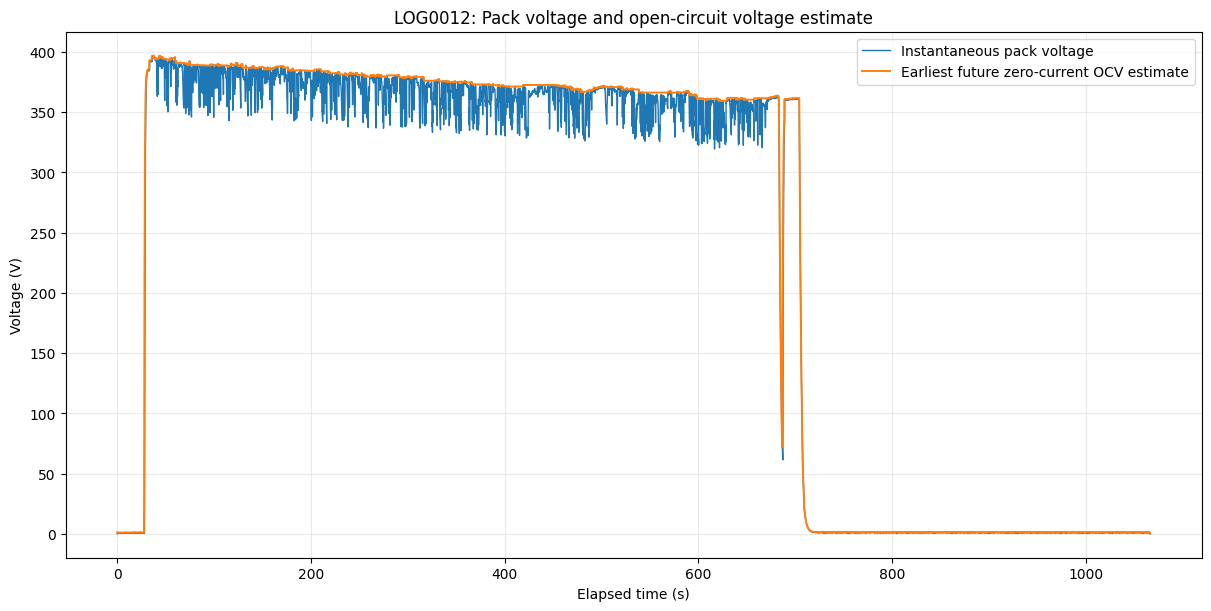

(<Figure size 1200x600 with 1 Axes>,
 <AxesSubplot: title={'center': 'LOG0012: Pack voltage and open-circuit voltage estimate'}, xlabel='Elapsed time (s)', ylabel='Voltage (V)'>)

In [38]:
plot_voltage_and_ocv(battery_df, log_id=log["log_id"], max_points=MAX_PLOT_POINTS)


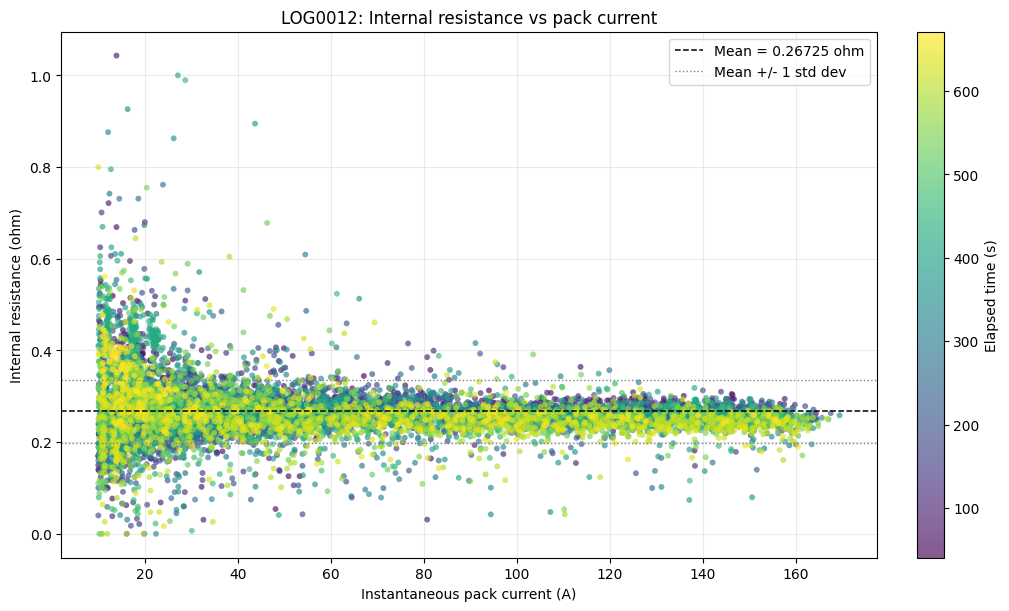

(<Figure size 1000x600 with 2 Axes>,
 <AxesSubplot: title={'center': 'LOG0012: Internal resistance vs pack current'}, xlabel='Instantaneous pack current (A)', ylabel='Internal resistance (ohm)'>)

In [39]:
plot_internal_resistance_vs_current(
    resistance_samples,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
)
